# 02 — Comparaison des modèles sur le nouvel historique Sentinel-2

Exécuter 01 avant 02. Baseline de persistance, Random Forest, XGBoost, LightGBM, LSTM, GRU et CNN-LSTM sur les mêmes exemples. DL : budgets 50/100/150, Early Stopping, deux configurations par budget. ML : trois configurations sélectionnées sur validation. Métriques MAE/RMSE/R², temps, courbes de loss, observé/prédit et écarts train-validation.

Aucun label de stress n’est disponible : Accuracy/F1/ROC ne sont pas calculables scientifiquement sur cette cible continue.

## 1. Choisir le mode d’exécution

**But :** Séparer le contrôle de préparation du lancement coûteux des modèles.

**Méthode et justification :** RUN_TRAINING=False charge et vérifie le pipeline. Mettre True pour entraîner. RUN_NAME horodaté distingue les expériences ; conserver le dossier et son protocole pour reproduire les résultats.

**Résultat attendu :** Une configuration explicite ; aucun entraînement complet par défaut.

In [1]:
from datetime import datetime
RUN_TRAINING=True  # True pour lancer la comparaison complète.
RUN_NAME='sentinel_2021_2025_'+datetime.now().strftime('%Y%m%d_%H%M%S')

## 2. Charger les outils scientifiques

**But :** Rassembler les bibliothèques et fixer la graine aléatoire.

**Méthode et justification :** scikit-learn fournit les métriques, la normalisation et Random Forest ; XGBoost/LightGBM les modèles boostés ; PyTorch les réseaux. La graine est fixée pour rendre les essais comparables, mais une seule graine ne démontre pas la stabilité statistique.

**Résultat attendu :** Les dépendances sont importées. Une erreur d’import doit être résolue avant l’entraînement.

In [2]:
"""Real multi-source olive benchmark; validation-only tuning, locked holdout tests."""
from pathlib import Path
import argparse
import copy
import hashlib
import html
import json
import platform
import time
import importlib.metadata
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
import torch
from torch import nn

ROOT=Path.cwd()
SEED=42

## 3. Définir LSTM, GRU et CNN-LSTM

**But :** Comparer trois architectures temporelles sur les mêmes séquences.

**Méthode et justification :** LSTM et GRU résument les six mois par un état caché. CNN-LSTM applique d’abord une convolution temporelle puis une LSTM. Le Dropout limite la dépendance excessive aux unités du réseau ; la sortie est un NDVI continu.

**Résultat attendu :** Trois architectures disponibles ; cette cellule définit les réseaux sans les entraîner.

In [3]:
class SequenceNet(nn.Module):
    def __init__(self, family, features, hidden, outputs):
        super().__init__()
        self.conv=nn.Conv1d(features,features,3,padding=1) if family=='CNN-LSTM' else None
        self.rnn=(nn.GRU if family=='GRU' else nn.LSTM)(features,hidden,batch_first=True)
        self.head=nn.Sequential(nn.Dropout(.15),nn.Linear(hidden,outputs))
    def forward(self,x):
        if self.conv is not None:
            x=torch.relu(self.conv(x.transpose(1,2))).transpose(1,2)
        out,_=self.rnn(x)
        return self.head(out[:,-1])

## 4. Définir les métriques

**But :** Quantifier les erreurs de prévision de façon comparable.

**Méthode et justification :** MAE : erreur absolue moyenne ; RMSE : pénalise davantage les grosses erreurs ; R² : explique le gain par rapport à une prédiction moyenne sur le jeu évalué et peut être négatif. MAE/RMSE sont exprimées en unités NDVI après inversion de la standardisation. Le code générique prévoit la classification, mais elle n’est pas activée sur cette tâche sans labels.

**Résultat attendu :** Des métriques de régression calculées sur chaque split.

In [4]:
def metrics(y,p,classification):
    if classification:
        labels=np.arange(p.shape[1])
        pred=p.argmax(axis=1)
        precision,recall,f1,_=precision_recall_fscore_support(y,pred,labels=labels,
            average='macro',zero_division=0)
        # One-vs-rest macro AUC; undefined if any class absent in test.
        auc=np.nan
        if len(np.unique(y))==len(labels):
            auc=roc_auc_score(y,p,multi_class='ovr',average='macro',labels=labels)
        return dict(accuracy=accuracy_score(y,pred),precision_macro=precision,
                    recall_macro=recall,f1_macro=f1,roc_auc_macro=auc)
    return dict(mae=mean_absolute_error(y,p),rmse=mean_squared_error(y,p)**.5,
                r2=r2_score(y,p) if len(y)>1 else np.nan)

## 5. Fixer le critère de sélection

**But :** Choisir les paramètres sans regarder les tests.

**Méthode et justification :** Pour ce problème de régression, on minimise la RMSE de validation. Les tests temporel et spatial sont réservés au bilan final.

**Résultat attendu :** Un critère unique pour comparer les essais.

In [5]:
def objective(y,p,classification):
    return 1-metrics(y,p,True)['f1_macro'] if classification else mean_squared_error(y,p)**.5

## 6. Préparer les graphiques observé/prédit

**But :** Comprendre les erreurs au-delà des scores moyens.

**Méthode et justification :** Le nuage observé/prédit doit se rapprocher de la diagonale. La seconde vue montre un segment d’exemples ordonnés par unité puis date ; ce n’est pas une courbe temporelle agrégée d’un seul champ. Les fonctions de confusion/ROC existent pour d’autres tâches, mais ne sont pas utilisées ici.

**Résultat attendu :** Des figures sauvegardées pour les tests temporel et spatial.

In [6]:
def plot_predictions(y,p,classification,path,title):
    if classification:
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        ConfusionMatrixDisplay(confusion_matrix(y,p.argmax(1),labels=np.arange(p.shape[1])),
            display_labels=['0%','25%','50%','100%']).plot(ax=axes[0],colorbar=False)
        for k in range(p.shape[1]):
            binary=(y==k).astype(int)
            if len(np.unique(binary))==2:
                fpr,tpr,_=roc_curve(binary,p[:,k])
                axes[1].plot(fpr,tpr,label=['0%','25%','50%','100%'][k])
        axes[1].plot([0,1],[0,1],'k--',alpha=.4)
        axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC one-vs-rest')
        axes[1].legend()
    else:
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        axes[0].scatter(y,p,s=12,alpha=.5)
        lo,hi=min(np.min(y),np.min(p)),max(np.max(y),np.max(p))
        axes[0].plot([lo,hi],[lo,hi],'k--')
        axes[0].set(xlabel='Observed',ylabel='Predicted')
        # Metadata order is unit/time; plot a bounded first-unit segment, not a
        # fictitious continuous aggregate time series across independent units.
        axes[1].plot(y[:80],label='Observed')
        axes[1].plot(p[:80],label='Predicted')
        axes[1].set(xlabel='Ordered test samples (unit then time)',ylabel='Target')
        axes[1].legend()
    fig.suptitle(title,fontsize=10)
    fig.tight_layout()
    fig.savefig(path,dpi=140)
    plt.close(fig)

## 7. Entraîner avec Early Stopping

**But :** Limiter le surapprentissage et comparer des budgets d’entraînement.

**Méthode et justification :** À chaque époque, le réseau apprend sur train par mini-lots, puis les pertes train/validation sont mesurées en mode évaluation. AdamW, Dropout, pénalisation des poids et écrêtage du gradient stabilisent l’apprentissage. La meilleure version selon la perte de validation est restaurée ; arrêt après 12 époques sans amélioration suffisante (min_delta=0,0001). Les budgets 50/100/150 sont des plafonds : un arrêt anticipé peut produire moins d’époques.

**Résultat attendu :** Un modèle au meilleur état de validation, son historique, l’époque retenue et son temps d’entraînement.

In [7]:
def train_dl(family,hidden,lr,cap,X,y,classification,classes):
    torch.manual_seed(SEED)
    rng=np.random.default_rng(SEED)
    model=SequenceNet(family,X['train'].shape[2],hidden,classes if classification else 1)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    criterion=nn.CrossEntropyLoss() if classification else nn.MSELoss()
    tx={k:torch.tensor(v,dtype=torch.float32) for k,v in X.items() if k in ['train','validation']}
    ty={k:torch.tensor(y[k],dtype=torch.long if classification else torch.float32)
        for k in ['train','validation']}
    best=float('inf'); state=None; wait=0; history=[]; best_epoch=0
    begin=time.perf_counter()
    for epoch in range(1,cap+1):
        model.train()
        for idx in np.array_split(rng.permutation(len(tx['train'])),max(1,int(np.ceil(len(tx['train'])/128)))):
            optimizer.zero_grad()
            out=model(tx['train'][idx])
            loss=criterion(out if classification else out[:,0],ty['train'][idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
        model.eval()
        with torch.no_grad():
            tr=model(tx['train']); va=model(tx['validation'])
            trloss=criterion(tr if classification else tr[:,0],ty['train']).item()
            valoss=criterion(va if classification else va[:,0],ty['validation']).item()
            row=dict(epoch=epoch,train_loss=trloss,validation_loss=valoss)
            if classification:
                row.update(train_accuracy=(tr.argmax(1)==ty['train']).float().mean().item(),
                    validation_accuracy=(va.argmax(1)==ty['validation']).float().mean().item())
        history.append(row)
        if valoss < best-1e-4:
            best=valoss; state=copy.deepcopy(model.state_dict()); wait=0; best_epoch=epoch
        else:
            wait+=1
        if wait>=12:
            break
    model.load_state_dict(state)
    model.eval()
    return model,pd.DataFrame(history),best_epoch,time.perf_counter()-begin

## 8. Préparer les tableaux du rapport

**But :** Présenter les résultats sous une forme lisible.

**Méthode et justification :** Les tableaux HTML regroupent les métriques et les temps ; leur formatage ne modifie pas les calculs.

**Résultat attendu :** Des tableaux utilisables dans le rapport final.

In [8]:
def table(df):
    return df.to_html(index=False,float_format=lambda x:f'{x:.4f}',border=0)

### Déroulement de la comparaison dans `main()`

1. **Intégrité et chargement** : vérifier les empreintes, charger les quatre splits préparés dans 01 et enregistrer les versions des bibliothèques.
2. **Normalisation** : ajuster StandardScaler des caractéristiques et de la cible uniquement sur train. Réutiliser ces paramètres pour les autres splits et sauvegarder les transformations. Les modèles ML reçoivent les mêmes six mois aplatis ; les modèles DL conservent la dimension temporelle.
3. **Baseline de persistance** : prévoir que le prochain NDVI sera égal au dernier NDVI observé. Un modèle complexe doit montrer un gain utile face à cette référence.
4. **Recherche ML** : essayer trois configurations de profondeur/taux d’apprentissage par famille (150 arbres), puis retenir la plus faible RMSE de validation. La forêt n’utilise pas de taux d’apprentissage.
5. **Recherche DL** : pour chaque architecture et plafond de 50/100/150 époques, essayer deux configurations (16 unités, lr=0,001 ; 32 unités, lr=0,003), avec Early Stopping. Les paramètres retenus et les époques réellement exécutées sont enregistrés.
6. **Évaluation** : calculer MAE, RMSE et R² sur train, validation, test temporel et groupes spatiaux réservés. Les tests ne sélectionnent ni paramètres ni budgets. Tous les modèles utilisent les mêmes exemples.
7. **Coûts** : mesurer le temps de l’essai retenu, le temps total de recherche et la médiane de cinq inférences sur le lot test, rapportée par exemple. Ces temps CPU dépendent du matériel et excluent le prétraitement de l’inférence.
8. **Surapprentissage** : comparer les scores train/validation et les courbes de loss. Un écart peut aussi venir du changement de saison/distribution ; ce n’est pas une preuve unique de surapprentissage.
9. **Choix final et sauvegarde** : choisir le modèle global par RMSE de validation, baseline comprise, puis présenter ses tests. Enregistrer modèles, transformations, prédictions, essais, courbes et protocole dans `outputs/benchmarks/<RUN_NAME>/`.

La grille est limitée et une seule graine est utilisée : la comparaison est expérimentale. Elle ne constitue ni une preuve de supériorité statistique ni un diagnostic validé de stress hydrique.


## 9. Orchestrer la comparaison complète

**But :** Appliquer le même protocole à la baseline et aux six familles de modèles.

**Méthode et justification :** Le détail de l’enchaînement est expliqué ci-dessous. Cette cellule définit main() ; le lancement effectif se fait à l’étape suivante.

**Résultat attendu :** Un pipeline prêt, dont les sorties restent séparées par expérience.

In [9]:
def main():
    parser=argparse.ArgumentParser()
    parser.add_argument('--run',default='multisource_20261103')
    parser.add_argument('--tasks',nargs='*')
    args=parser.parse_args(['--run', RUN_NAME, '--tasks', 'sentinel_ndvi'])
    out=ROOT/'outputs/benchmarks'/args.run
    out.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(2)
    manifests=json.loads((ROOT/'data/processed/model_inputs_sentinel/suite_manifest.json').read_text(encoding='utf-8'))
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch','xgboost','lightgbm']}
    rows=[]; trial_rows=[]; sections=[]
    for manifest in manifests:
        name=manifest['name']
        if args.tasks and name not in args.tasks:
            continue
        dest=out/name
        if (dest/'completed.json').exists():
            rows.extend(json.loads((dest/'completed.json').read_text()))
            continue
        dest.mkdir(exist_ok=True)
        folder=ROOT/'data/processed/model_inputs_sentinel'/name
        for file,checksum in manifest['files_sha256'].items():
            assert hashlib.sha256((folder/file).read_bytes()).hexdigest()==checksum
        print('START',name,flush=True)
        data=np.load(folder/'samples.npz')
        splits=['train','validation','test','independent']
        raw={s:data['X_'+s] for s in splits}
        y={s:data['y_'+s] for s in splits}
        classification=manifest['kind']=='classification'
        classes=len(np.unique(y['train'])) if classification else 1
        scaler=StandardScaler().fit(raw['train'].reshape(-1,raw['train'].shape[-1]))
        X={s:scaler.transform(v.reshape(-1,v.shape[-1])).reshape(v.shape).astype(np.float32) for s,v in raw.items()}
        ys=StandardScaler().fit(y['train'].reshape(-1,1)) if not classification else None
        yscaled={s:ys.transform(v.reshape(-1,1))[:,0].astype(np.float32) if ys else v.astype(int) for s,v in y.items()}
        flat={s:v.reshape(len(v),-1) for s,v in X.items()}
        joblib.dump(dict(features=scaler,target=ys),dest/'transformations.joblib')
        local=[]
        def evaluate(label,predict,fit_seconds,search_seconds,validation_objective,params,extra=None):
            predictions={s:predict(s) for s in splits}
            # Median warm inference on full test batch; excludes data preparation.
            timings=[]
            for _ in range(5):
                begin=time.perf_counter(); predict('test'); timings.append(time.perf_counter()-begin)
            inference=float(np.median(timings))
            for split in splits:
                result=dict(dataset=name,model=label,split=split,n=len(y[split]),
                    fit_seconds=fit_seconds,search_seconds=search_seconds,
                    inference_ms_per_sample=inference/len(y['test'])*1000,
                    validation_objective=validation_objective,params=json.dumps(params),
                    **metrics(y[split],predictions[split],classification))
                if extra: result.update(extra)
                local.append(result)
            meta=pd.read_csv(folder/'samples.csv')
            for split in ['test','independent']:
                frame=meta[meta.split.eq(split)].copy()
                frame['observed']=y[split]
                p=predictions[split]
                frame['predicted']=p.argmax(1) if classification else p
                if classification:
                    for k in range(classes):frame[f'probability_{k}']=p[:,k]
                frame.to_csv(dest/f'{label}_{split}_predictions.csv',index=False)
                plot_predictions(y[split],p,classification,dest/f'{label}_{split}.png',f'{name} | {label} | {split}')
            print(name,label,'val',round(validation_objective,5),flush=True)

        # Baseline uses same origins and same horizon as every model.
        begin=time.perf_counter()
        if classification:
            baseline=DummyClassifier(strategy='prior').fit(flat['train'],y['train'])
            base_predict=lambda s:baseline.predict_proba(flat[s])
        elif name=='olea_yield':
            baseline=DummyRegressor(strategy='mean').fit(flat['train'],y['train'])
            base_predict=lambda s:baseline.predict(flat[s])
        else:
            index=manifest['features'].index({'csic_moisture':'Hd 25 cm','drought_spad':'Average_SPAD','sentinel_ndvi':'NDVI'}[name])
            base_predict=lambda s:raw[s][:,-1,index]
        elapsed=time.perf_counter()-begin
        evaluate('Baseline',base_predict,elapsed,elapsed,objective(y['validation'],base_predict('validation'),classification),{})
        for family in ['RandomForest','XGBoost','LightGBM']:
            best=None; tuning_start=time.perf_counter()
            for depth,rate in [(3,.03),(5,.05),(8,.1)]:
                cls=dict(RandomForest=RandomForestClassifier,XGBoost=XGBClassifier,LightGBM=LGBMClassifier) if classification else dict(RandomForest=RandomForestRegressor,XGBoost=XGBRegressor,LightGBM=LGBMRegressor)
                params=dict(n_estimators=150,max_depth=depth,random_state=SEED,n_jobs=2)
                if family!='RandomForest':params['learning_rate']=rate
                if family=='LightGBM':params.update(verbosity=-1,min_child_samples=5,num_leaves=min(31,2**depth),deterministic=True,force_col_wise=True)
                if family=='XGBoost':params.update(tree_method='hist',verbosity=0)
                model=cls[family](**params)
                begin=time.perf_counter(); model.fit(flat['train'],y['train']); elapsed=time.perf_counter()-begin
                p=model.predict_proba(flat['validation']) if classification else model.predict(flat['validation'])
                score=objective(y['validation'],p,classification)
                trial_rows.append(dict(dataset=name,model=family,params=json.dumps(params),validation_objective=score,fit_seconds=elapsed))
                if best is None or score<best[0]:best=(score,model,params,elapsed)
            search=time.perf_counter()-tuning_start
            score,model,params,elapsed=best
            joblib.dump(model,dest/f'{family}.joblib')
            predict=lambda s,m=model:m.predict_proba(flat[s]) if classification else m.predict(flat[s])
            evaluate(family,predict,elapsed,search,score,params)
        if manifest['kind']!='cross_sectional_regression':
            for family in ['LSTM','GRU','CNN-LSTM']:
                for cap in [50,100,150]:
                    best=None; tuning_start=time.perf_counter()
                    for hidden,lr in [(16,.001),(32,.003)]:
                        model,history,best_epoch,elapsed=train_dl(family,hidden,lr,cap,X,yscaled,classification,classes)
                        def predict(s,m=model):
                            with torch.no_grad():
                                result=m(torch.tensor(X[s],dtype=torch.float32))
                                if classification:return torch.softmax(result,1).numpy()
                                return ys.inverse_transform(result.numpy())[:,0]
                        score=objective(y['validation'],predict('validation'),classification)
                        params=dict(hidden=hidden,lr=lr,epoch_cap=cap,patience=12,min_delta=.0001,seed=SEED)
                        trial_rows.append(dict(dataset=name,model=family,params=json.dumps(params),validation_objective=score,fit_seconds=elapsed,best_epoch=best_epoch,epochs_run=len(history)))
                        if best is None or score<best[0]:best=(score,model,history,best_epoch,elapsed,params)
                    search=time.perf_counter()-tuning_start
                    score,model,history,best_epoch,elapsed,params=best
                    label=f'{family}_{cap}'
                    torch.save(dict(state_dict=model.state_dict(),params=params,features=manifest['features'],outputs=classes),dest/f'{label}.pt')
                    history.to_csv(dest/f'{label}_history.csv',index=False)
                    fig,axes=plt.subplots(1,2 if classification else 1,figsize=(10,4) if classification else (6,4))
                    axes=np.atleast_1d(axes)
                    history.plot(x='epoch',y=['train_loss','validation_loss'],ax=axes[0])
                    axes[0].axvline(best_epoch,color='gray',ls='--'); axes[0].set_title(label+' | loss')
                    if classification:history.plot(x='epoch',y=['train_accuracy','validation_accuracy'],ax=axes[1])
                    fig.tight_layout();fig.savefig(dest/f'{label}_learning.png',dpi=140);plt.close(fig)
                    def predict(s,m=model):
                        with torch.no_grad():
                            result=m(torch.tensor(X[s],dtype=torch.float32))
                            if classification:return torch.softmax(result,1).numpy()
                            return ys.inverse_transform(result.numpy())[:,0]
                    evaluate(label,predict,elapsed,search,score,params,dict(best_epoch=best_epoch,epochs_run=len(history)))
        (dest/'completed.json').write_text(json.dumps(local,indent=2),encoding='utf-8')
        rows.extend(local)
    results=pd.DataFrame(rows)
    results.to_csv(out/'comparison.csv',index=False)
    pd.DataFrame(trial_rows).to_csv(out/'hyperparameter_trials.csv',index=False)
    protocol=dict(seed=SEED,versions=versions,python=platform.python_version(),platform=platform.platform(),
        epoch_caps=[50,100,150],dl_configs=[dict(hidden=16,lr=.001),dict(hidden=32,lr=.003)],
        selection='Minimum validation RMSE or maximum validation macro F1. Test never used in tuning.',
        timing='Training and search wall times; median of five warm test batch predictions per sample; CPU, 2 threads.',
        limitations='Single seed, small tuning grid; no statistical superiority claim. Data tasks cannot be pooled or ranked by raw metrics.',
        datasets=manifests)
    (out/'protocol.json').write_text(json.dumps(protocol,indent=2,ensure_ascii=False),encoding='utf-8')
    # Select the family + epoch budget using validation only, then show both tests.
    selected=[]
    for name,group in results[results.split.eq('validation')].groupby('dataset'):
        winner=group.loc[group.validation_objective.idxmin()]
        selected.append(dict(dataset=name,selected_model=winner.model,validation_objective=winner.validation_objective))
    pd.DataFrame(selected).to_csv(out/'validation_selected_models.csv',index=False)
    body=['<h1>OliveSmart — comparaison multi-datasets réels</h1>',
        '<p>Chaque tâche est évaluée séparément. Les traitements d’irrigation ne sont pas des diagnostics de stress. '
        'Optimisation sur validation uniquement ; baseline incluse dans la sélection. Une seule graine, grille limitée : résultats exploratoires.</p>']
    for manifest in manifests:
        name=manifest['name']; subset=results[results.dataset.eq(name)]
        if subset.empty:continue
        winner=next(x['selected_model'] for x in selected if x['dataset']==name)
        body += [f'<h2>{html.escape(name)}</h2>',f'<p>{html.escape(manifest["description"])}</p>',
                 f'<p>Modèle retenu par validation : <strong>{winner}</strong>.</p>',
                 '<p>Effectifs : '+html.escape(str(manifest['counts']))+'</p>',
                 '<ul>'+''.join('<li>'+html.escape(s)+'</li>' for s in manifest['limitations'])+'</ul>']
        if name=='olea_yield':body.append('<p>LSTM / GRU / CNN-LSTM : NON APPLICABLES — séries répétées insuffisantes. Split transversal par arbres, pas chronologique.</p>')
        cols=['model','split','n','accuracy','precision_macro','recall_macro','f1_macro','roc_auc_macro'] if name=='drought_irrigation' else ['model','split','n','mae','rmse','r2']
        cols+=['fit_seconds','search_seconds','inference_ms_per_sample']
        body.append(table(subset[subset.split.isin(['test','independent'])][cols]))
        train=subset[subset.split.eq('train')].set_index('model')
        val=subset[subset.split.eq('validation')].set_index('model')
        score='f1_macro' if name=='drought_irrigation' else 'rmse'
        gap=(train[[score]].rename(columns={score:'train_'+score}).join(val[[score]].rename(columns={score:'validation_'+score})))
        gap['validation_minus_train']=gap['validation_'+score]-gap['train_'+score]
        gap.to_csv(out/name/'overfitting.csv')
        body+=['<h3>Surapprentissage / changement de saison</h3>',table(gap.reset_index()),
            '<p>Écart train-validation descriptif : il peut refléter surapprentissage et changement de distribution. '
            'Les pertes DL sont calculées en mode évaluation ; la régression est standardisée sur train.</p>']
        for split in ['test','independent']:
            body.append(f'<img src="{name}/{winner}_{split}.png" alt="Observed predictions or confusion and ROC">')
        if (out/name/f'{winner}_learning.png').exists():body.append(f'<img src="{name}/{winner}_learning.png" alt="Training and validation curves">')
        body.append('<p>Sources : '+', '.join(f'<a href="{s}">{s}</a>' for s in manifest['provenance'])+'</p>')
    body+=['<h2>Interprétation OliveSmart</h2><p>Le modèle est sélectionné uniquement par RMSE de validation, baseline comprise. Comparer ensuite son gain sur le test temporel et les groupes spatiaux réservés. Un seul seed et une petite grille ne démontrent pas une supériorité statistique. Le NDVI ne constitue pas une vérité terrain de stress hydrique.</p>']
    (out/'rapport.html').write_text('<!doctype html><html lang="fr"><meta charset="utf-8"><title>OliveSmart multi-datasets</title>'
        '<style>body{font:15px system-ui;max-width:1400px;margin:35px auto;padding:20px;color:#16352b}table{border-collapse:collapse;font-size:12px}th,td{padding:7px;border-bottom:1px solid #ddd}img{max-width:100%;display:block;margin:25px 0}h2{margin-top:50px}</style>'
        +''.join(body)+'</html>',encoding='utf-8')
    print('DONE',out,flush=True)

## 10. Vérifier les entrées et lancer si demandé

**But :** Éviter de lancer des modèles sur des données périmées ou modifiées.

**Méthode et justification :** Les fichiers exportés par 01 doivent exister et leurs empreintes doivent correspondre au manifeste. RUN_TRAINING=True appelle main() ; False affiche les effectifs et confirme que le pipeline est prêt. Une préparation modifiée implique une nouvelle expérience.

**Résultat attendu :** Confirmation des entrées ; puis, seulement si activé, entraînement de la comparaison.

In [10]:
prep=ROOT/'data/processed/model_inputs_sentinel'
assert (prep/'suite_manifest.json').exists(), 'Exécuter le notebook 01.'
manifest=json.loads((prep/'suite_manifest.json').read_text(encoding='utf-8'))[0]
for f,h in manifest['files_sha256'].items():
    assert hashlib.sha256((prep/'sentinel_ndvi'/f).read_bytes()).hexdigest()==h
print('Entrées vérifiées :',manifest['counts'])
print('Entraînement demandé :',RUN_TRAINING)
if RUN_TRAINING:
    main()
else:
    print('Prêt : mettre RUN_TRAINING=True puis exécuter les cellules pour entraîner.')

Entrées vérifiées : {'independent': 338, 'test': 1340, 'train': 8507, 'validation': 1341}
Entraînement demandé : True
START sentinel_ndvi
sentinel_ndvi Baseline val 0.08349
sentinel_ndvi RandomForest val 0.086
sentinel_ndvi XGBoost val 0.08857
sentinel_ndvi LightGBM val 0.08875
sentinel_ndvi LSTM_50 val 0.08299
sentinel_ndvi LSTM_100 val 0.08299
sentinel_ndvi LSTM_150 val 0.08299
sentinel_ndvi GRU_50 val 0.08375
sentinel_ndvi GRU_100 val 0.08375
sentinel_ndvi GRU_150 val 0.08375
sentinel_ndvi CNN-LSTM_50 val 0.08227
sentinel_ndvi CNN-LSTM_100 val 0.08227
sentinel_ndvi CNN-LSTM_150 val 0.08227
DONE C:\Users\ASUS\Desktop\emsi2\MICROSERVICES\SmartOlive_Sate\outputs\benchmarks\sentinel_2021_2025_20261103_140650


## 11. Lire les résultats et les courbes

**But :** Choisir un modèle utile pour OliveSmart et identifier ses limites.

**Méthode et justification :** Comparer séparément test temporel et test spatial. Chercher des erreurs faibles, un gain face à la baseline et des coûts raisonnables. R² négatif ou absence de gain n’est pas un échec du pipeline : le modèle complexe n’est alors pas justifié. Les courbes affichent les époques réellement exécutées. Le rapport HTML contient les figures observé/prédit ; il est aussi consultable depuis le dossier de sortie.

**Résultat attendu :** Tableaux de comparaison, rapport et courbes après l’entraînement. En mode False, cette cellule ne produit pas de résultats de modèles.

,dataset,model,split,n,fit_seconds,search_seconds,inference_ms_per_sample,validation_objective,params,mae,rmse,r2,best_epoch,epochs_run
2,sentinel_ndvi,Baseline,test,1340,0.000007,0.000007,5.223880e-07,0.083490,{},0.052125,0.075983,0.807230,NaN,NaN
3,sentinel_ndvi,Baseline,independent,338,0.000007,0.000007,5.223880e-07,0.083490,{},0.053136,0.071194,0.830443,NaN,NaN
6,sentinel_ndvi,RandomForest,test,1340,8.183745,14.591777,2.642022e-02,0.086001,"{""n_estimators"": 150, ""max_depth"": 8, ""random_...",0.039576,0.063957,0.863420,NaN,NaN
7,sentinel_ndvi,RandomForest,independent,338,8.183745,14.591777,2.642022e-02,0.086001,"{""n_estimators"": 150, ""max_depth"": 8, ""random_...",0.040824,0.057483,0.889464,NaN,NaN
10,sentinel_ndvi,XGBoost,test,1340,0.247102,2.076351,1.135821e-03,0.088572,"{""n_estimators"": 150, ""max_depth"": 3, ""random_...",0.040649,0.063837,0.863935,NaN,NaN
11,sentinel_ndvi,XGBoost,independent,338,0.247102,2.076351,1.135821e-03,0.088572,"{""n_estimators"": 150, ""max_depth"": 3, ""random_...",0.042155,0.058512,0.885473,NaN,NaN
14,sentinel_ndvi,LightGBM,test,1340,0.108234,0.600022,2.796567e-03,0.088750,"{""n_estimators"": 150, ""max_depth"": 3, ""random_...",0.040576,0.064016,0.863169,NaN,NaN
15,sentinel_ndvi,LightGBM,independent,338,0.108234,0.600022,2.796567e-03,0.088750,"{""n_estimators"": 150, ""max_depth"": 3, ""random_...",0.042303,0.058886,0.884001,NaN,NaN
18,sentinel_ndvi,LSTM_50,test,1340,8.579086,24.826726,2.137687e-03,0.082991,"{""hidden"": 32, ""lr"": 0.003, ""epoch_cap"": 50, ""...",0.036337,0.060257,0.878765,27.0,39.0
19,sentinel_ndvi,LSTM_50,independent,338,8.579086,24.826726,2.137687e-03,0.082991,"{""hidden"": 32, ""lr"": 0.003, ""epoch_cap"": 50, ""...",0.036039,0.051221,0.912236,27.0,39.0


model,split,n,mae,rmse,r2,fit_seconds,search_seconds,inference_ms_per_sample
Baseline,test,1340,0.0521,0.0760,0.8072,0.0000,0.0000,0.0000
Baseline,independent,338,0.0531,0.0712,0.8304,0.0000,0.0000,0.0000
RandomForest,test,1340,0.0396,0.0640,0.8634,8.1837,14.5918,0.0264
RandomForest,independent,338,0.0408,0.0575,0.8895,8.1837,14.5918,0.0264
XGBoost,test,1340,0.0406,0.0638,0.8639,0.2471,2.0764,0.0011
XGBoost,independent,338,0.0422,0.0585,0.8855,0.2471,2.0764,0.0011
LightGBM,test,1340,0.0406,0.0640,0.8632,0.1082,0.6000,0.0028
LightGBM,independent,338,0.0423,0.0589,0.8840,0.1082,0.6000,0.0028
LSTM_50,test,1340,0.0363,0.0603,0.8788,8.5791,24.8267,0.0021
LSTM_50,independent,338,0.0360,0.0512,0.9122,8.5791,24.8267,0.0021


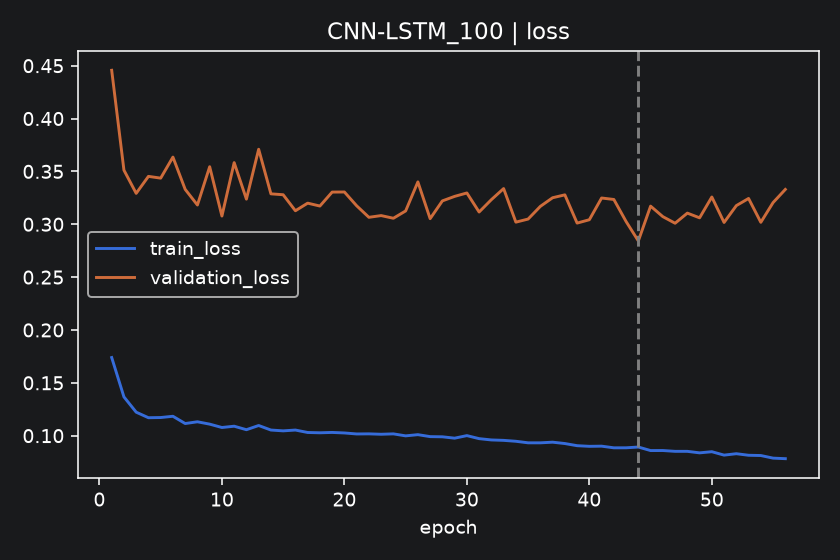

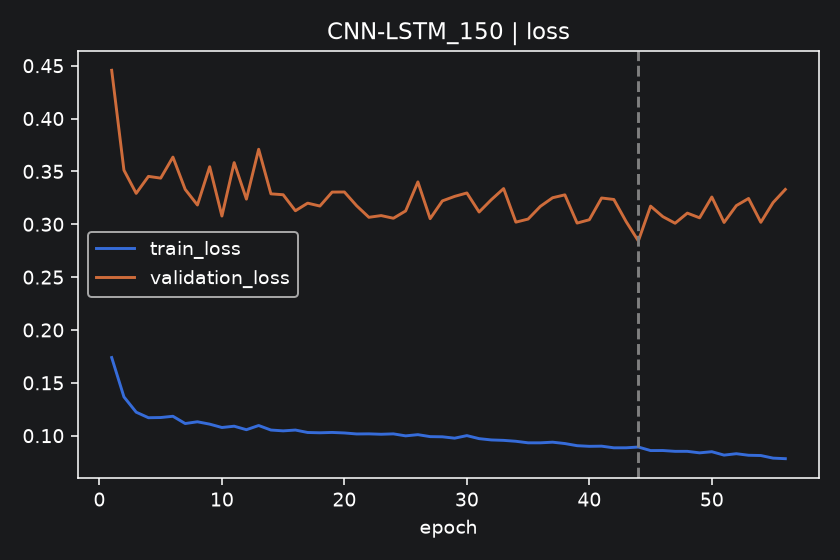

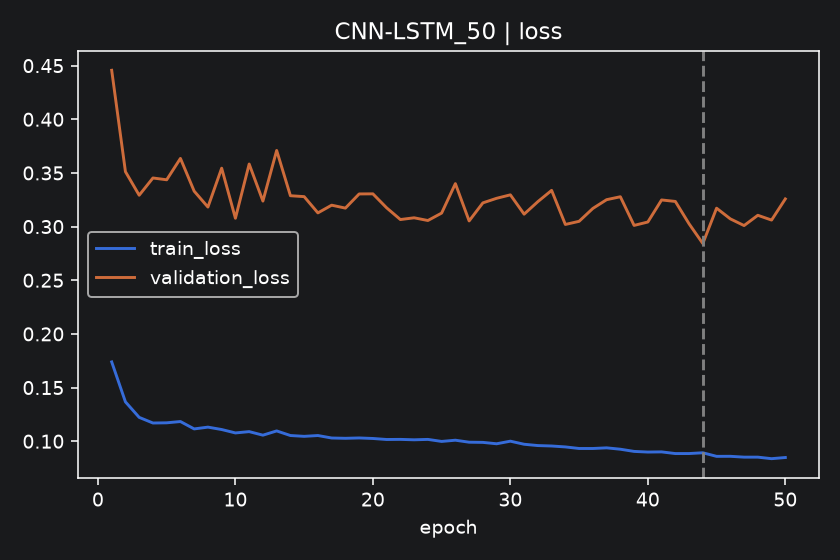

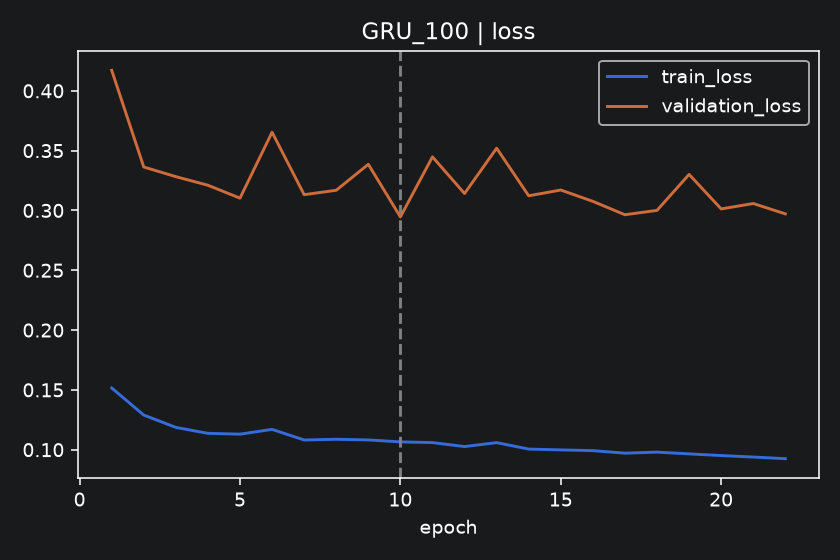

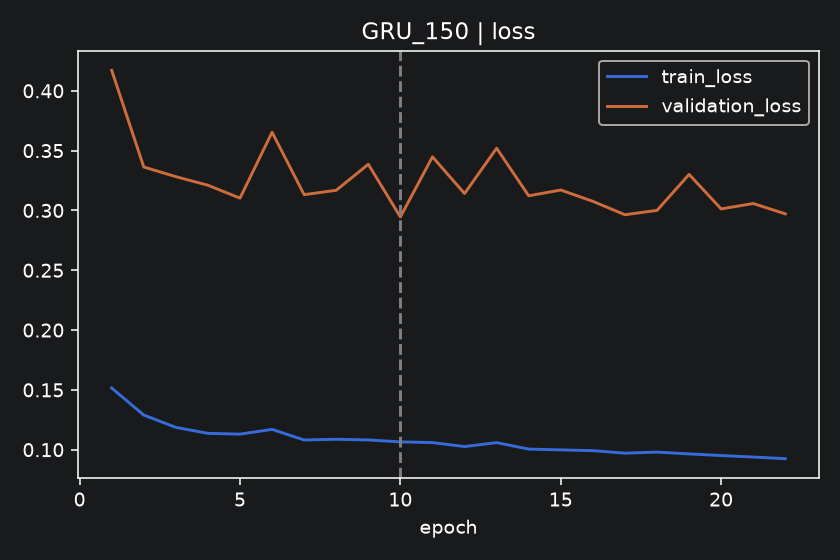

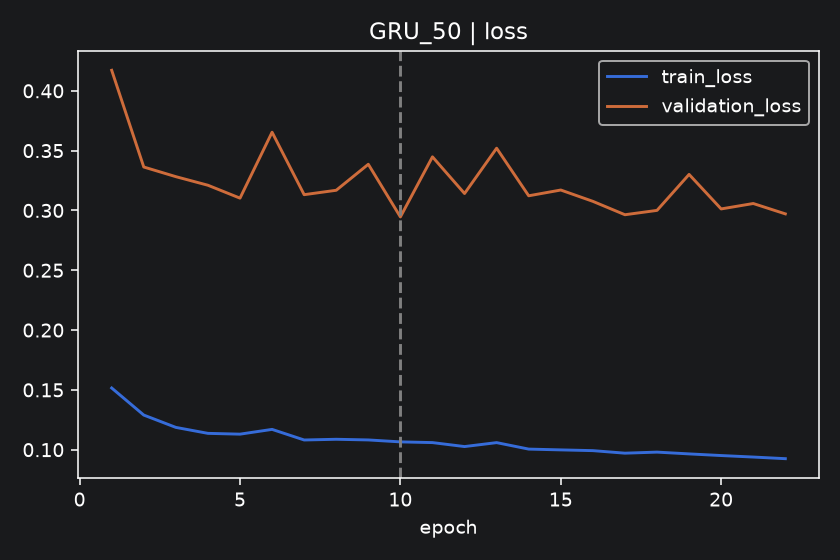

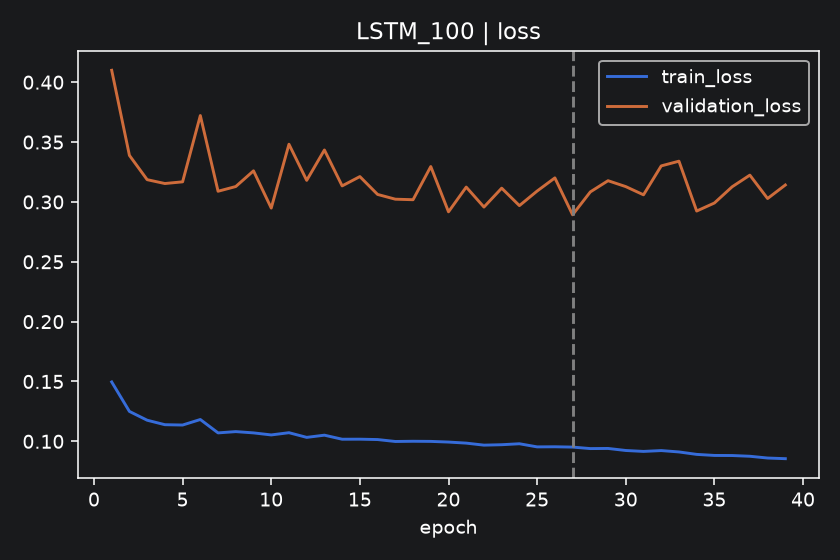

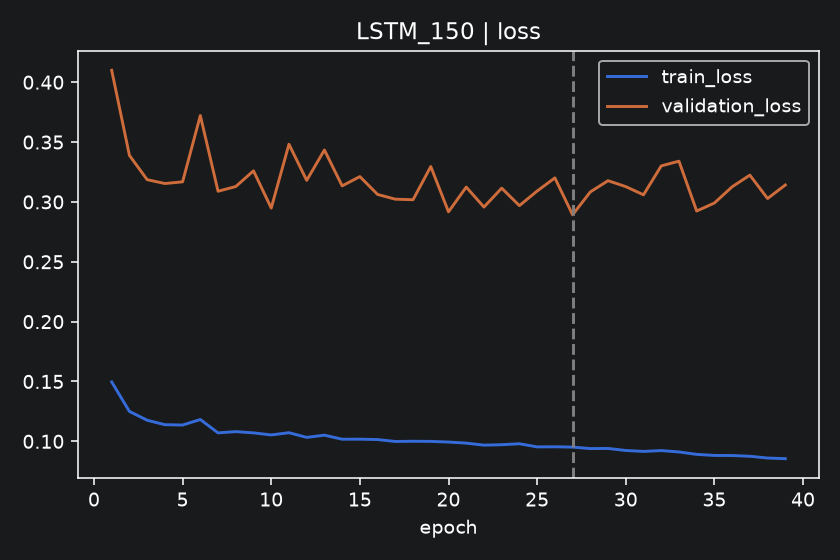

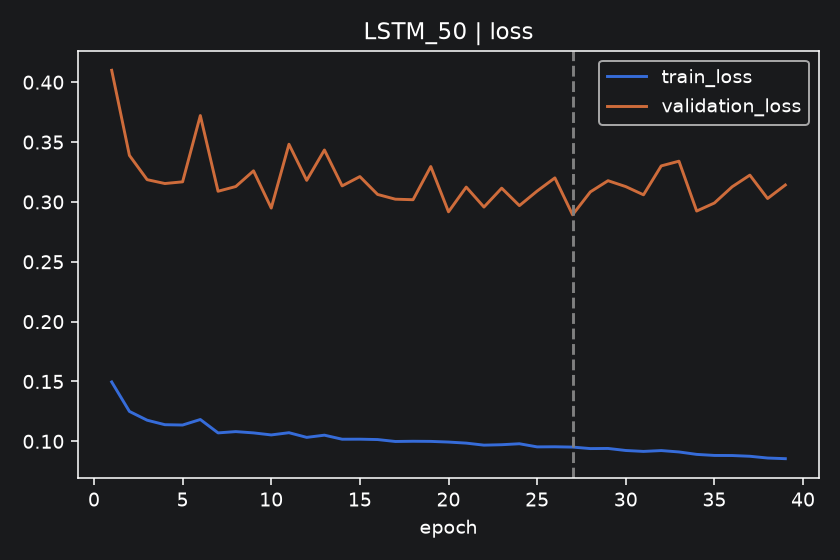

Rapport et modèles sauvegardés : C:\Users\ASUS\Desktop\emsi2\MICROSERVICES\SmartOlive_Sate\outputs\benchmarks\sentinel_2021_2025_20261103_140650


In [11]:
if RUN_TRAINING:
    from IPython.display import display, HTML, Image
    result=ROOT/'outputs/benchmarks'/RUN_NAME
    comparison=pd.read_csv(result/'comparison.csv')
    display(comparison[comparison.split.isin(['test','independent'])])
    display(HTML((result/'rapport.html').read_text(encoding='utf-8')))
    for path in sorted((result/'sentinel_ndvi').glob('*learning.png')):
        display(Image(filename=str(path)))
    print('Rapport et modèles sauvegardés :',result)